In [1]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch

In [2]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return hours, minutes

def load_eddies(dir_eddies):
    """Load cyclonic and anticyclonic eddy shapefiles."""

    anti = {}
    cyc = {}

    for fname in os.listdir(dir_eddies):

        if "anti" in fname:
            target = anti
        else:
            target = cyc

        if "maxspeed" in fname:
            target["maxspeed"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "outcontour" in fname:
            target["outcontour"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "centers" in fname:
            target["centers"] = gpd.read_file(os.path.join(dir_eddies, fname))

    return anti, cyc

def load_satellite(adt_path):

    # ds = xr.open_dataset(adt_daily_dir + file_adt)
    ds = xr.open_dataset(adt_path)
    if "time" in ds:
        ds = ds.drop_vars("time")

    return {
        "dataset": ds,
        "lon": ds.longitude,
        "lat": ds.latitude,
        "adt": ds.adt,
        "ugos": np.squeeze(ds.ugos),
        "vgos": np.squeeze(ds.vgos)
    }

def average_adcp_velocity(curr_day):

    u = curr_day.uvel_adcp.values
    v = curr_day.vvel_adcp.values

    mask = (
        ~np.isnan(u).any(axis=1)
        &
        ~np.isnan(v).any(axis=1)
    )

    u_mean = np.full(u.shape[0], np.nan)
    v_mean = np.full(v.shape[0], np.nan)

    u_mean[mask] = u[mask].mean(axis=1)
    v_mean[mask] = v[mask].mean(axis=1)

    return u_mean, v_mean

def velocity_magnitude(u, v):
    return np.sqrt(u**2 + v**2)

def interpolate_satellite(curr_day, ugos, vgos):

    u = ugos.interp(
        longitude=curr_day.lon_adcp,
        latitude=curr_day.lat_adcp,
        method="nearest"
    )

    v = vgos.interp(
        longitude=curr_day.lon_adcp,
        latitude=curr_day.lat_adcp,
        method="nearest"
    )

    return u, v

def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs
        )

In [3]:
date = '2026-07-07'
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
ship_center = (dm_to_dd(11, 32.559), dm_to_dd(38, 30.074, True))
# station_6 = (11.892700, -39.216100)
# station_6 = (11.541100, -38.4758007)
sab_3 = (11.1800, -39.24000)

glider_deployment = (11.54, -37.41)
# s1_x, s1_y = sab_1
# s2_x, s2_y = station_6
s3_x, s3_y = sab_3
ship_x, ship_y = ship_center

In [14]:
##### POSITION VARIABLES #####
ft=10

lon_min, lon_max, lat_min, lat_max = 10, 20, -42, -34
pos_west,pos_east,pos_south,pos_north  = 10, 20, -42,-34  #Reset the area
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [15]:
dir = f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/"

dir_adcp = "/Volumes/science/MD252_WHIRLS/ADCP_FROM_XAVIER/MD2_OS38_WHIRLS-2026_120s_oceansites.nc"
# sst_path = dir + f"Eddies/{date}/sst/BT_masked_Meteosat_{date.replace("-", "")}.nc"
sst_path = "/Volumes/science/MD252_WHIRLS/GOFLOW/goflow_daily_mean_20260705.nc"
dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
save_fig = dir + f"daily_figures/{date}/"
if not os.path.isdir(save_fig):
    os.makedirs(save_fig)

fname_bathy = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/bathymetry/etopo2.nc"
ctd_path = "/Volumes/science/MD252_WHIRLS/CTD/data/"

date_adt="2026-07-02"
adt_path= f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date_adt}/ssh/{date_adt}_cmems_data.nc"


In [16]:
adt_data = nc.Dataset(adt_path)
lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_15095/4160332479.py:8: RuntimeWarning: invalid value encountered in sqrt
  current_mag = np.sqrt(ugos**2 + vgos**2)


In [17]:
sst_data = xr.open_dataset(sst_path)
lats_sst = sst_data['lat']
lons_sst = sst_data['lon']
# time = sst_data['time']
sst = sst_data['BT_masked_max']

sst = np.where(sst==np.nan, 0, sst)

In [18]:
##### Load Eddies #####
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

In [19]:
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
ship_center = (longs_bato[-1], lat_bato[-1])
ship_x, ship_y = ship_center
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [20]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [21]:
depth_subset = np.where(depth_subset > 0, 0, depth_subset)

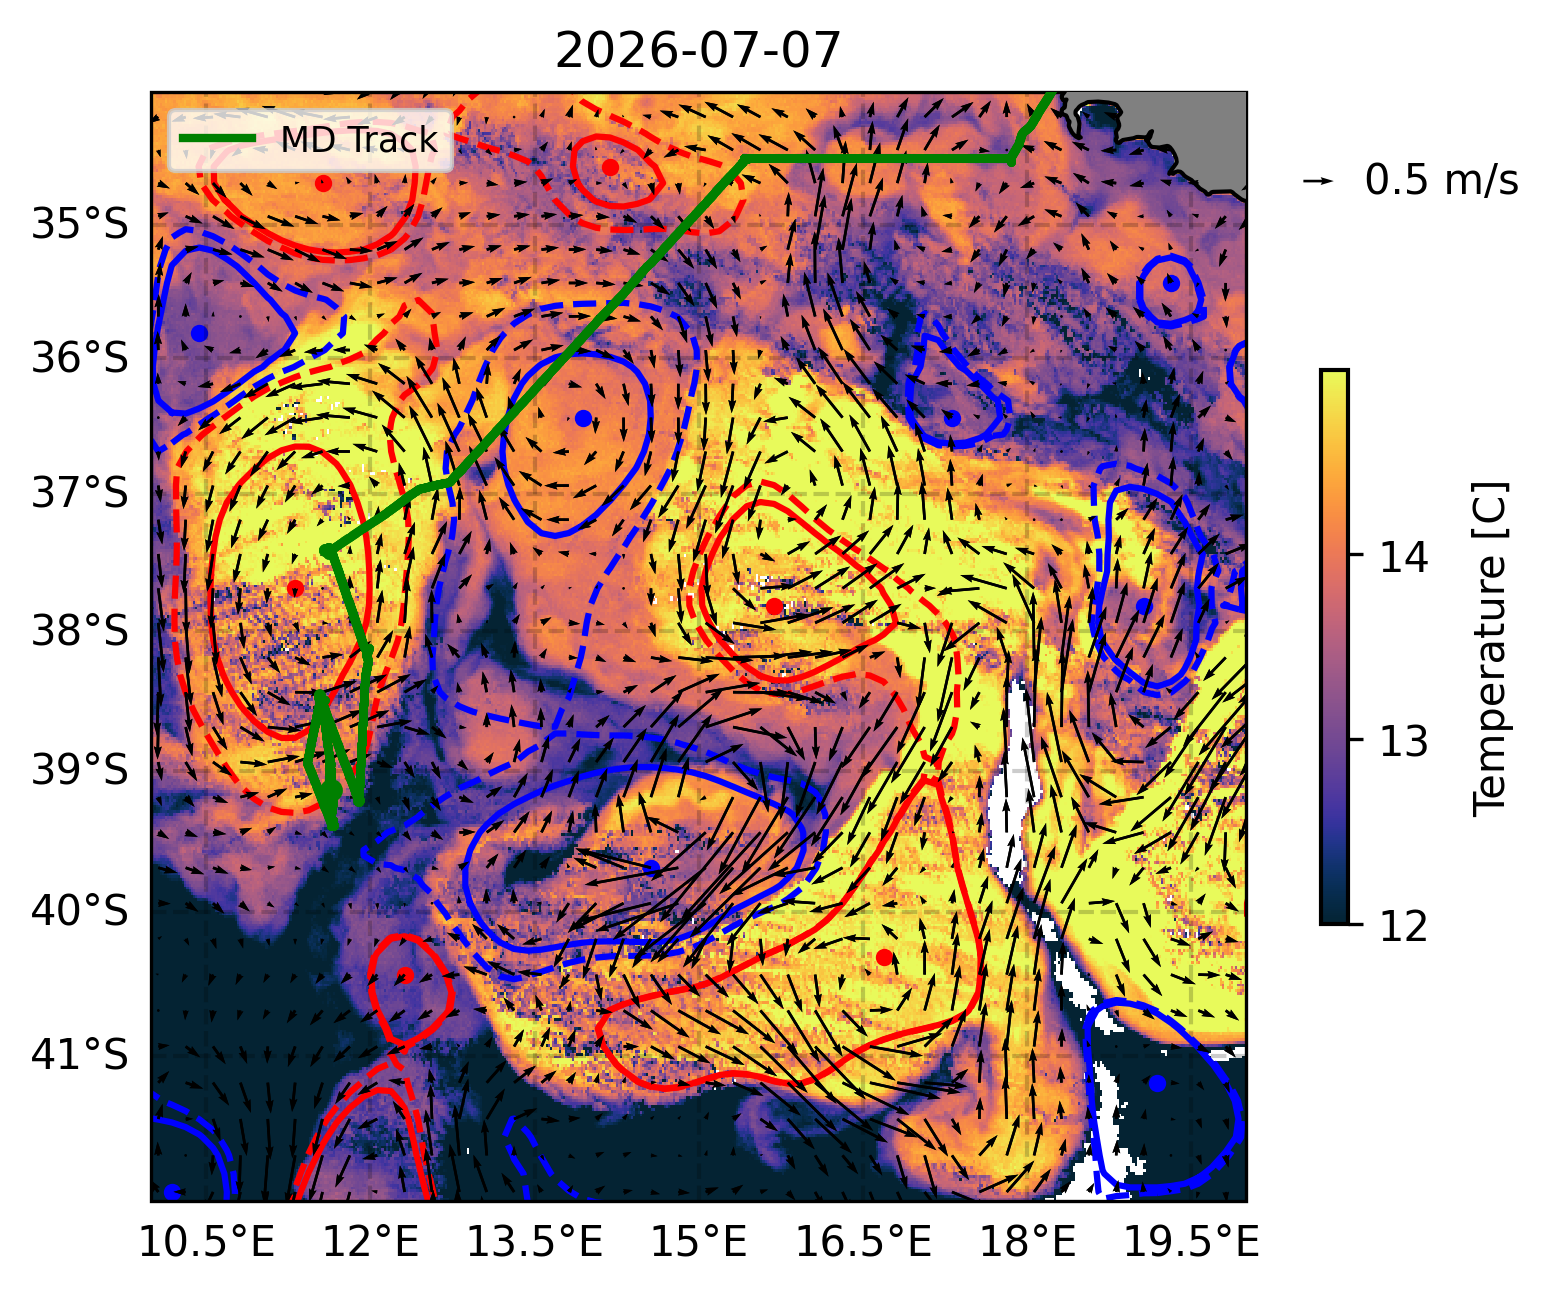

In [30]:
lon_min, lon_max, lat_min, lat_max = 10, 20, -42, -34
pos_west,pos_east,pos_south,pos_north  = 10, 20, -42,-34  #Reset the area
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# SST contours
lon2d, lat2d = np.meshgrid(lons_sst, lats_sst)
c2 = ax0.pcolormesh(lon2d, lat2d, sst[:,:], vmin=12, vmax=15, cmap=cmocean.cm.thermal,
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)


# Streamlines
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

# Ship path
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)


# Eddies
plot_eddies(ax0, anti, "red", crs)
plot_eddies(ax0, cyc, "blue", crs)

# Colorbar
cbar = fig.colorbar(c2, ax=ax0, shrink=0.5)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(12, 15, 1))
cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)
# Legend
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0],[0],color="green",lw=2,label="MD Track")
]


leg = ax0.legend(
    handles=legend_handles,
    loc="upper left", fontsize="small"
)
leg.set_zorder(100) 

In [ ]:
# speed_knots = 6.0
# stop_hours = 2.0

# points = [
#     (ship_x, ship_y),
#     # (s1_x, s1_y),
#     # (s2_x, s2_y),
#     (s3_x, s3_y),
# ]

# total_time = 0.0
# times = []  # cumulative arrival times

# for i in range(1, len(points)):
#     lon1, lat1 = points[i-1]
#     lon2, lat2 = points[i]

#     dist_nm = haversine_nm(lon1, lat1, lon2, lat2)
#     travel_time = dist_nm / speed_knots  # hours

#     total_time += travel_time

#     # arrival at point i
#     times.append(total_time)

#     # add stop time except after final point
#     if i < len(points) - 1:
#         total_time += stop_hours
# curr_t = datetime.now()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


IndexError: list index out of range

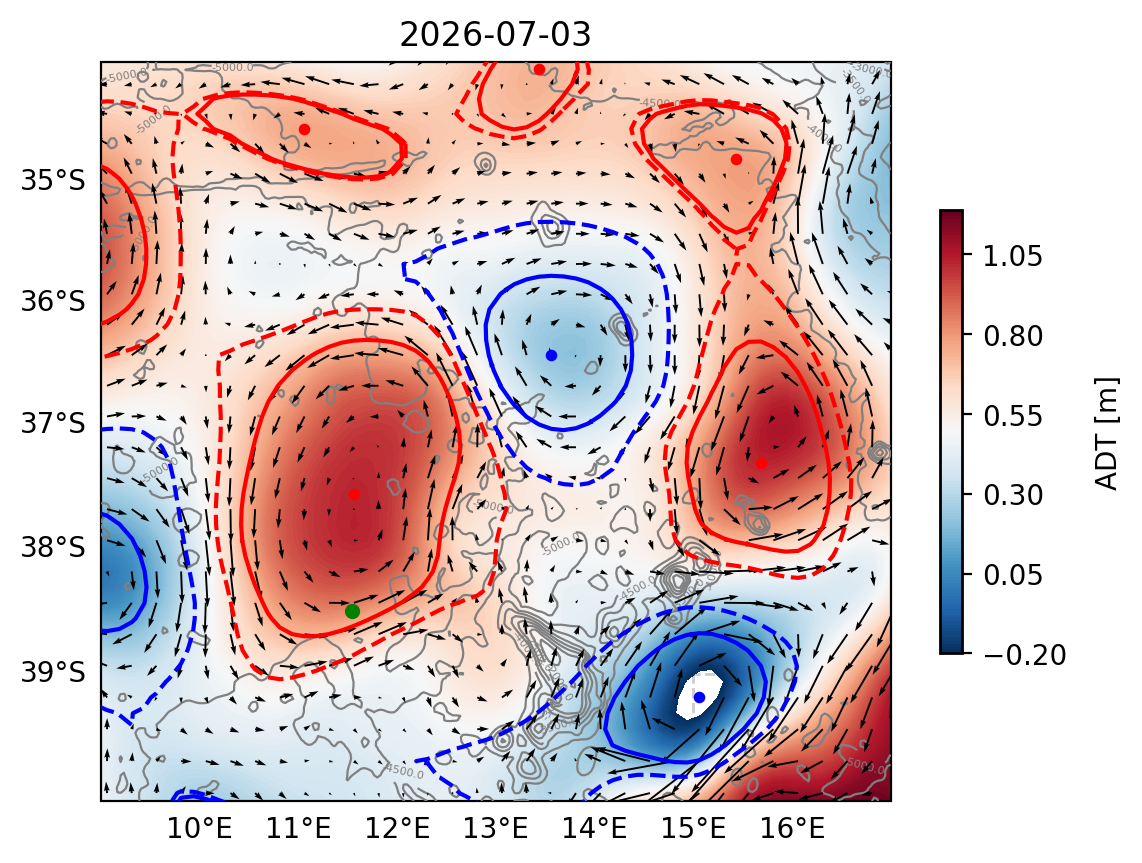

In [78]:
fig = plt.figure(dpi=200)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)
# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")

h, m = format_time(times[0])
upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s1_x, s1_y, s=20, color='orange', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}")

# ax0.annotate(
#         "S6",
#         xy=(s1_x, s1_y),
#         xycoords=crs,
#         xytext=(5, -3),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='orange',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# h, m = format_time(times[1])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s2_x, s2_y, s=20, color='lime', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}")
# ax0.annotate(
#         "S7",
#         xy=(s2_x, s2_y),
#         xycoords=crs,
#         xytext=(-4, 5),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='lime',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
h, m = format_time(times[2])
upd_t = curr_t + timedelta(hours=h, minutes=m)
ax0.scatter(s3_x, s3_y, s=20, color='lime', zorder=20, transform=crs,
            label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}0")
ax0.annotate(
        "S8",
        xy=(s3_x, s3_y),
        xycoords=crs,
        xytext=(-14, -4.5),  # <-- offset in points (RIGHT, UP)
        textcoords='offset points',
        fontsize='x-small',
        color='indigo',
        ha='left',
        va='bottom',
        zorder=101,
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="black",
            linewidth=0.5,
            alpha=0.8
        )
    )
# ax0.annotate(
#     '',
#     xy=(s1_x, s1_y), xytext=(ship_x, ship_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='orange', lw=2),
#     zorder=19
# )
# # Arrow from Cast 1 to Cast 2
# ax0.annotate(
#     '',
#     xy=(s2_x, s2_y), xytext=(s1_x, s1_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='lime', lw=2),
#     zorder=19
# )

# Arrow from Cast 2 to Cast 3
ax0.annotate(
    '',
    xy=(s3_x, s3_y), xytext=(ship_x, ship_y),
    xycoords=crs._as_mpl_transform(ax0),
    textcoords=crs._as_mpl_transform(ax0),
    arrowprops=dict(arrowstyle='->', color='indigo', lw=2),
    zorder=19
)
# ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_adt_{title}.png")

In [22]:
lats_sst.shape

(550,)

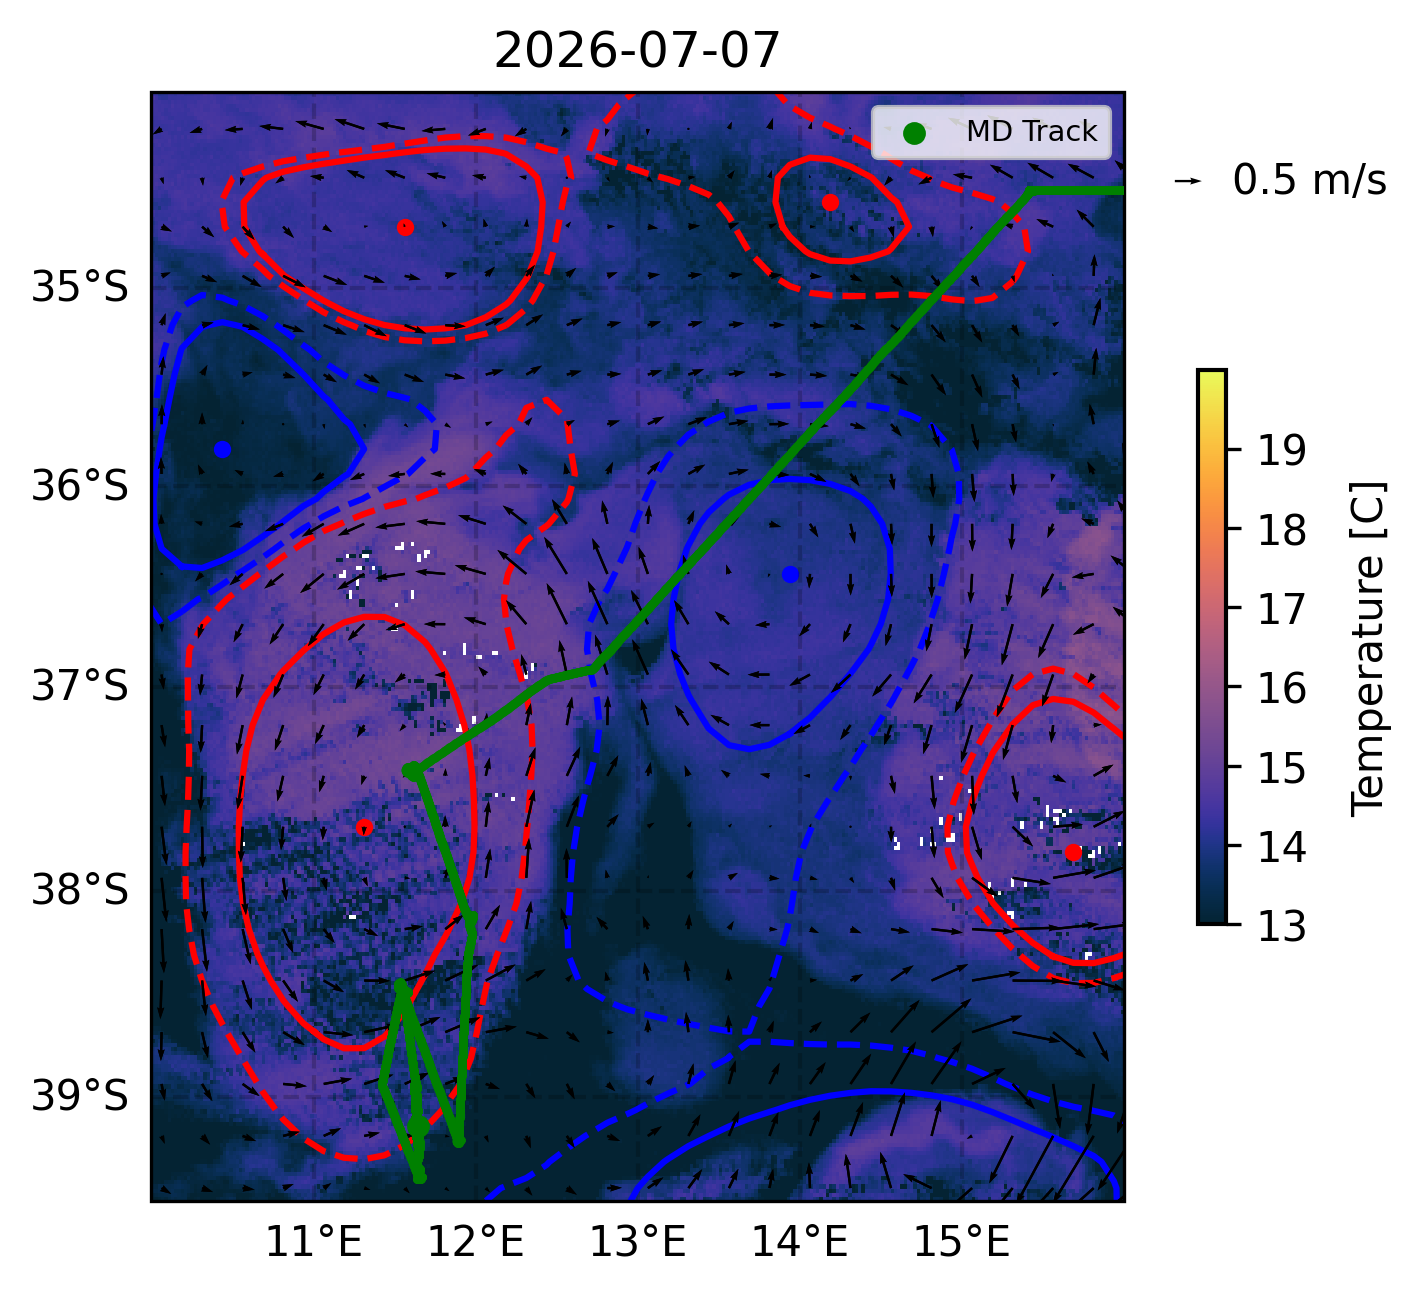

In [27]:
print(lons_sst.min(), lons_sst.max())

ValueError: zero-size array to reduction operation fmin which has no identity

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


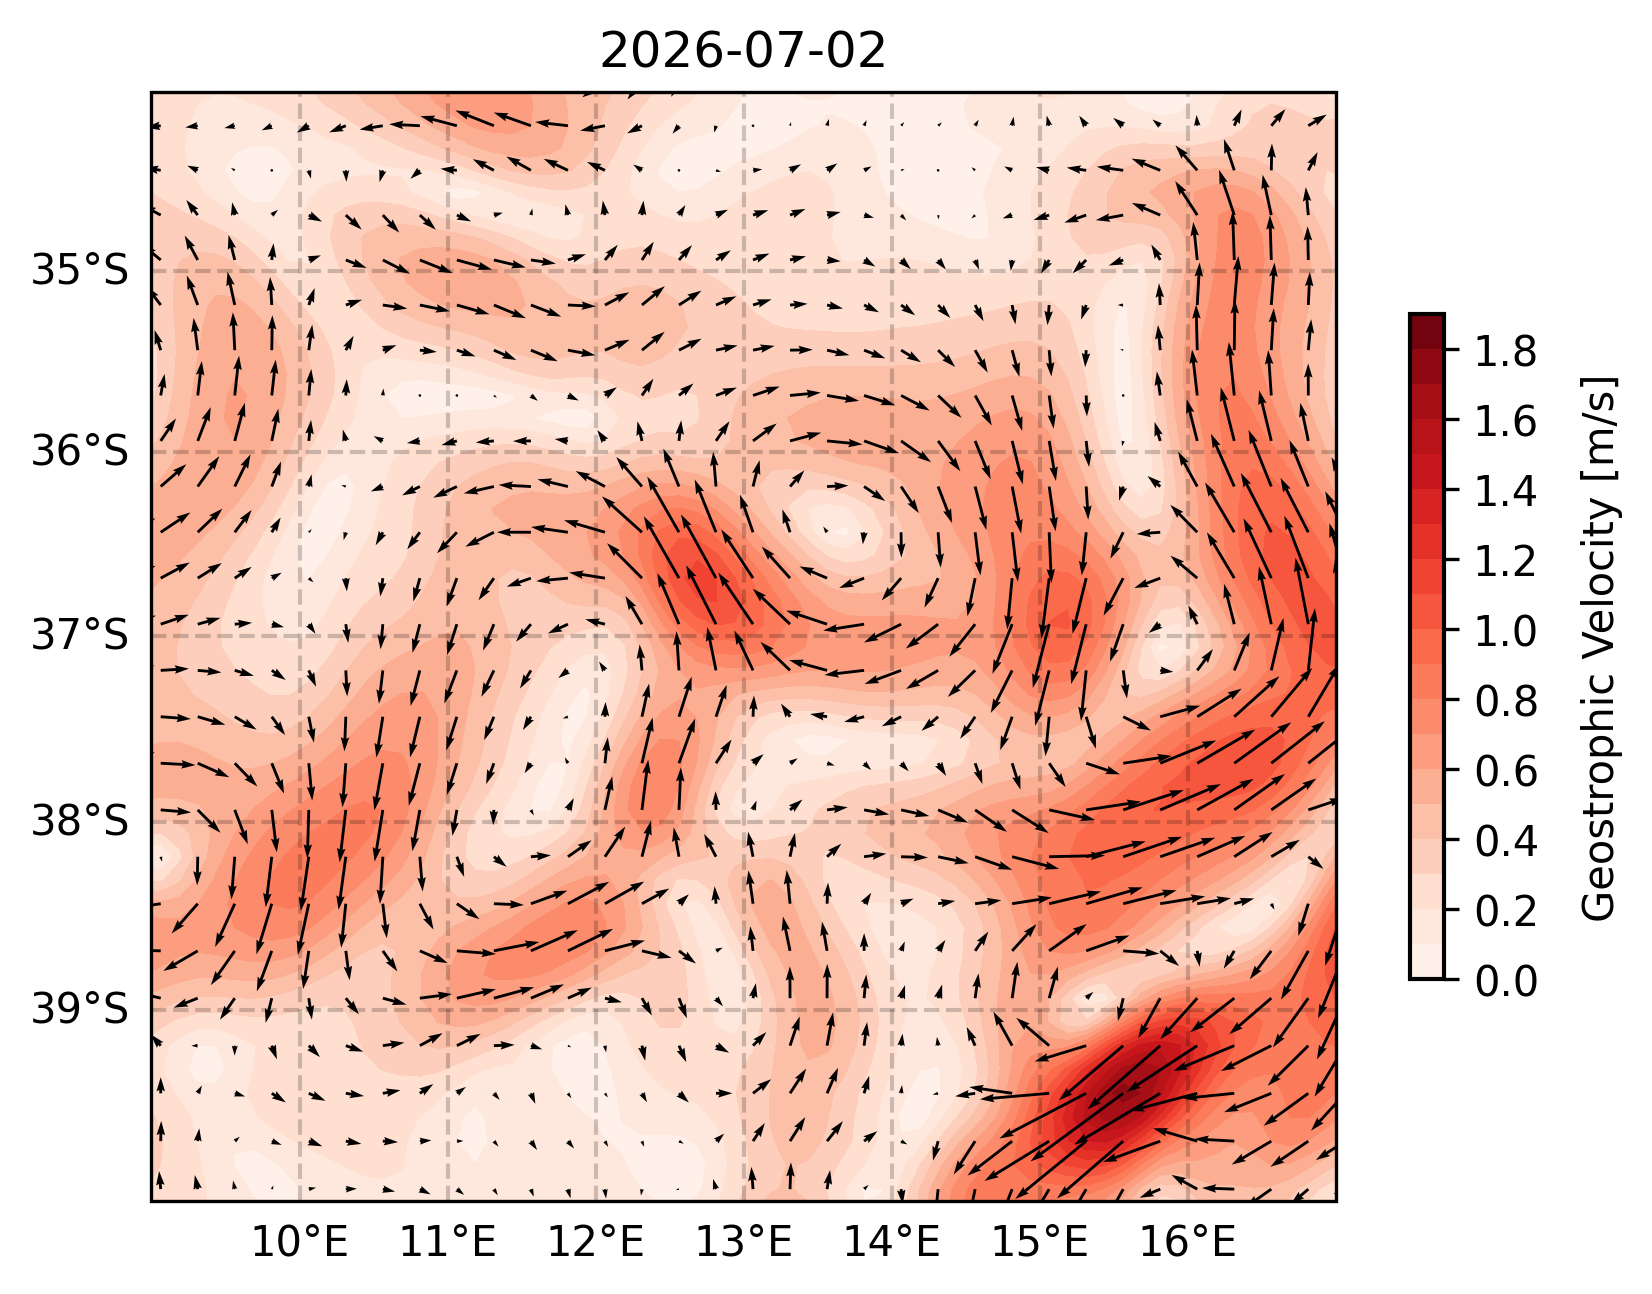

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

c2 = ax0.contourf(lons, lats, current_mag,  levels=np.arange(0, 2.0, 0.05), cmap='Reds',
            transform=crs, linestyles='dashed', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(0, 2.0, 0.2))
cbar.set_label('Geostrophic Velocity [m/s]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

In [89]:
current_mag.shape

(156, 180)

In [ ]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="black", linestyles='solid', transform=crs, linewidths=0.8)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="Current Position")
ax0.scatter(s1_x, s1_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s1_x, s1_y}")
ax0.scatter(s2_x, s2_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s2_x, s2_y}")
ax0.scatter(s3_x, s3_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s3_x, s3_y}")
# ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, label="MD Track", color='black', zorder=90)
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_adt_{title}.png")